# IndoBERTweet — Metadata (sesi Stage 1)

**Sebelum run:** pastikan `splits.csv` (hasil `00_make_splits.ipynb`) sudah ada di `DATA_DIR`.

Perubahan dari versi sebelumnya:
- Split train/val/test diambil dari `splits.csv` (berbasis `text_id`), sama untuk semua notebook → tidak ada leakage dan test set identik.
- Fitur polarisasi bisa dimatikan lewat `USE_POLARIZATION` (default `False`).
- Teks dipotong ke panjang yang sama (`TEXT_MAX_TOKENS`) di text-only maupun metadata.
- Stage 2: `weight_decay` sekarang dipakai; `class_weight_alpha` dihapus karena memang tidak berpengaruh.
- Final training bisa diulang beberapa seed (`FINAL_SEEDS`), dan prediksi test disimpan ke `preds_*.csv` untuk `99_compare.ipynb`.
- Nama study Optuna & file `.db` baru, supaya tidak memakai trial lama dari split yang bocor.

**Sesi ini:** jalankan dari atas sampai selesai bagian *Stage 1* (berhenti sebelum *Stage 2*). Isi kodenya sama persis dengan file `stg2`.


In [1]:
! pip install -q optuna
! pip install -q emoji
! pip install -q iterative-stratification

In [2]:
import pandas as pd
import numpy as np
import ast
import re
import gc
import os
import sys
import math
import shutil
import random
import matplotlib.pyplot as plt

import torch
from torch import nn
import datasets
from datasets import Dataset
import optuna
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix)
from scipy.special import softmax
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, EarlyStoppingCallback, TrainerCallback, set_seed)
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import disable_progress_bars

hf_logging.set_verbosity_error()          # laporan load model, warning transformers
hf_logging.disable_progress_bar()         # "Writing model shards", "Loading weights"
disable_progress_bars()                   # progress bar download dari Hugging Face Hub
datasets.disable_progress_bars()          # progress bar "Map"
optuna.logging.set_verbosity(optuna.logging.WARNING)   # log bawaan Optuna per trial

In [3]:
# ===================== KONFIGURASI =====================
MODEL_NAME = "indolem/indobertweet-base-uncased"
MODEL_TAG  = "indobertweet"
SETUP      = "meta"            # "text" = text-only (majority vote), "meta" = teks + metadata annotator

# False = eksperimen utama tanpa fitur polarisasi (label polarisasi tidak tersedia saat deployment).
# True  = ablasi dengan polarisasi, supaya bisa dibandingkan dengan hasil lama.
USE_POLARIZATION = False

DATA_DIR       = "/kaggle/input/datasets/evelynuntariady/thesis"
OUT_DIR        = "/kaggle/working"
PREPROCESS_DIR = DATA_DIR                       # folder berisi preprocess.py
DATA_FILE      = f"{DATA_DIR}/explode_dataset_using_latest_cleaned_text.csv"
SPLIT_FILE     = f"{DATA_DIR}/splits_grouped.csv"     # hasil 00_make_splits.ipynb

SEED          = 42
FINAL_SEEDS   = [42]        # disarankan [42, 43, 44] kalau waktu GPU cukup
N_TRIALS      = 10
N_TRIALS_S2   = 10
LOGGING_STEPS = 10
TEXT_MAX_TOKENS = 126       # panjang teks maks (token), sama untuk text-only & metadata

# Kolom metadata annotator yang dimasukkan ke prefix: {nama kolom: label di prefix}.
# Hapus/comment baris untuk eksperimen ablasi (mis. hanya etnis + domisili + agama).
# Kalau dikosongkan ({}) dan USE_POLARIZATION=False, model = text-only versi explode.
META_COLS = {
    "ethnicity": "Etnis",
    "religion": "Agama",
    "disability": "Disabilitas",
    "lgbt": "LGBT",
    "gender": "Gender",
    "age": "Usia",
    "domisili": "Domisili",
    "pendidikan terakhir": "Pendidikan",
    "status pekerjaan": "Pekerjaan",
    "president vote leaning": "Preferensi politik",
}
META_TAG = "all"
# Setup pembanding (opsional), ganti META_COLS & META_TAG:
#   {"agama_seg": "Agama", "usia_seg": "Usia", "pendidikan_seg": "Pendidikan", "gender": "Gender"}  -> META_TAG = "rel-age-edu-gen"
ID_COLS = ["text_id", "annotator_id"]
DEMO_SAVE_COLS = ['ethnicity', 'religion', 'disability', 'lgbt', 'gender', 'age', 'domisili', 'pendidikan terakhir', 'status pekerjaan', 'president vote leaning', 'domisili_seg']   # disimpan di file prediksi untuk analisis per kelompok
LABEL_COLS = [
    "insults",
    "identity_attack",
    "threat_incitement_to_violence",
    "profanity_obscenity",
    "sexually_explicit",
]

RUN_TAG = "_".join(x for x in [MODEL_TAG, SETUP, META_TAG, "pol" if USE_POLARIZATION else "nopol"] if x)
os.makedirs(OUT_DIR, exist_ok=True)
print("RUN_TAG:", RUN_TAG)

RUN_TAG: indobertweet_meta_all_nopol


# Load & Prepare Data

In [4]:
df = pd.read_csv(DATA_FILE, dtype={"text_id": str})
df = df.drop(columns=['Unnamed: 0', 'key'], errors='ignore')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53989 entries, 0 to 53988
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0.1                   53989 non-null  int64 
 1   text_id                        53989 non-null  object
 2   annotator_id                   53989 non-null  int64 
 3   text                           53988 non-null  object
 4   topic                          53989 non-null  object
 5   is_noise_or_spam_text          53989 non-null  int64 
 6   toxicity                       53989 non-null  int64 
 7   polarized                      53989 non-null  int64 
 8   profanity_obscenity            53989 non-null  int64 
 9   threat_incitement_to_violence  53989 non-null  int64 
 10  insults                        53989 non-null  int64 
 11  identity_attack                53989 non-null  int64 
 12  sexually_explicit              53989 non-null  int64 
 13  c

In [5]:
df_main = df[df['is_noise_or_spam_text'] == 0]
df_main = df_main[df_main['is_valid'] == 1]
df_main = df_main.dropna().copy()

# --- Bersihkan nilai metadata (ada spasi di ujung, mis. "Banda Aceh ", "Mataram ") ---
for c in ["ethnicity", "religion", "disability", "lgbt", "gender", "domisili",
          "pendidikan terakhir", "status pekerjaan", "president vote leaning"]:
    df_main[c] = df_main[c].astype(str).str.strip()
df_main["ethnicity"] = df_main["ethnicity"].replace({"Balinese": "Bali"})
df_main["age"] = df_main["age"].astype(int)

# --- Kolom segmentasi (hasil metadata_analysis.ipynb) ---
JABODETABEK = {"Jakarta", "Bogor", "Depok", "Tangerang", "Bekasi"}
df_main["domisili_seg"] = np.where(df_main["domisili"].isin(JABODETABEK), "Jabodetabek", "Luar Jabodetabek")
# Kolom di bawah tidak dipakai di setup utama, disediakan kalau mau menambah setup pembanding
df_main["agama_seg"] = np.where(df_main["religion"].isin(["Islam", "Syiah", "Ahmadiyah"]), "Islam", "Non-Islam")
df_main["usia_seg"] = df_main["age"].apply(lambda a: "Gen Z" if a <= 27 else ("Milenial" if a <= 43 else "Gen X"))
df_main["pendidikan_seg"] = df_main["pendidikan terakhir"].map({
    "Sekolah Menengah Atas (SMA)": "SMA", "Diploma": "Diploma/S1", "Sarjana (S1)": "Diploma/S1",
    "Magister (S2)": "S2/S3", "Doktor (S3)": "S2/S3"})

print("Domisili setelah dibersihkan:", sorted(df_main["domisili"].unique()))
print(df_main.groupby("domisili_seg")["annotator_id"].nunique().rename("jumlah annotator"))

print("Jumlah baris (teks x annotator):", len(df_main))
print("Jumlah teks unik               :", df_main['text_id'].nunique())
print("Jumlah annotator               :", df_main['annotator_id'].nunique())
print(df_main['toxicity'].value_counts())

Domisili setelah dibersihkan: ['Banda Aceh', 'Bandung', 'Bogor', 'Depok', 'Jakarta', 'Madura', 'Magelang', 'Makassar', 'Mataram', 'Medan', 'Padang', 'Pontianak', 'Riau', 'Sumedang', 'Tangerang', 'Ternate']
domisili_seg
Jabodetabek         13
Luar Jabodetabek    19
Name: jumlah annotator, dtype: int64
Jumlah baris (teks x annotator): 50963
Jumlah teks unik               : 26503
Jumlah annotator               : 32
toxicity
0    41732
1     9231
Name: count, dtype: int64


In [6]:
df_main[['text_id','domisili_seg']].duplicated().sum()

np.int64(16434)

In [7]:
if META_TAG != "all":
    keys = ["text_id", "domisili_seg"]
    df_main["toxicity_asli"] = df_main["toxicity"]
    df_main["toxicity"] = (df_main.groupby(keys)["toxicity_asli"].transform("mean") > 0.5).astype(int)
    for l in LABEL_COLS:
        hanya_toxic = df_main[l].where(df_main["toxicity_asli"] == 1)
        df_main[l] = (hanya_toxic.groupby([df_main[k] for k in keys]).transform("mean") > 0.5).astype(int)
    df_main = df_main.drop_duplicates(subset=keys).drop(columns=["toxicity_asli"]).reset_index(drop=True)

print("Baris:", len(df_main), "| teks:", df_main["text_id"].nunique())
print(df_main.groupby("text_id").size().value_counts().sort_index())

Baris: 50963 | teks: 26503
1     14885
2      5514
3      4004
4      1169
5       351
6       157
7        33
8         2
9        14
10       19
11       30
12       30
13       90
14       36
15       76
16       19
17       55
18        2
19       17
Name: count, dtype: int64


In [8]:
df_main[['text_id','domisili_seg']].duplicated().sum()

np.int64(16434)

In [9]:
df_main.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50963 entries, 0 to 53988
Data columns (total 29 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0.1                   50963 non-null  int64 
 1   text_id                        50963 non-null  object
 2   annotator_id                   50963 non-null  int64 
 3   text                           50963 non-null  object
 4   topic                          50963 non-null  object
 5   is_noise_or_spam_text          50963 non-null  int64 
 6   toxicity                       50963 non-null  int64 
 7   polarized                      50963 non-null  int64 
 8   profanity_obscenity            50963 non-null  int64 
 9   threat_incitement_to_violence  50963 non-null  int64 
 10  insults                        50963 non-null  int64 
 11  identity_attack                50963 non-null  int64 
 12  sexually_explicit              50963 non-null  int64 
 13  cleane

# Text Cleaning

In [10]:
sys.path.append(PREPROCESS_DIR)   # folder yang berisi preprocess.py
from preprocess import preprocess_text
from tqdm import tqdm
tqdm.pandas()

SOURCE_COL = "cleaned_text"
df_main["processed_text"] = (
    df_main[SOURCE_COL].fillna("").astype(str).progress_apply(preprocess_text)
)
pd.set_option("display.max_colwidth", 150)
df_main[[SOURCE_COL, "processed_text"]].sample(5, random_state=42)

100%|██████████| 50963/50963 [00:14<00:00, 3574.05it/s]


,cleaned_text,processed_text
17525,China akan mengontrol total penggunaan batu bara dan membatasi proyek-proyek beremisi tinggi untuk meningkatkan kualitas udara. Menurut sebuah ren...,china akan mengontrol total penggunaan batu bara dan membatasi proyek proyek beremisi tinggi untuk meningkatkan kualitas udara. menurut sebuah ren...
14217,Link live streaming Timnas Indonesia U24 vs China Taipei di Asian Games 2022: misi pertahankan puncak klasemen,link live streaming timnas indonesia u vs china taipei di asian games misi pertahankan puncak klasemen
31691,KSTP selalu berbuat ulah dengan merampok dana desa yang harusnya bisa dinikmati masyarakat. Dukung pemberantasan KST Papua agar mereka dibubarkan ...,kstp selalu berbuat ulah dengan merampok dana desa yang harusnya bisa dinikmati masyarakat. dukung pemberantasan kst papua agar mereka dibubarkan ...
21275,Para pemuda Tiongkok (RRC) akan membanjiri posisi ASN di Indonesia,para pemuda tiongkok rrc akan membanjiri posisi asn di indonesia
49010,Film Lightyear dilarang tayang di 14 negara Timur Tengah dan Asia terkait adanya adegan LGBT. Bagaimana menurut kalian?,film lightyear dilarang tayang di negara timur tengah dan asia terkait adanya adegan lgbt. bagaimana menurut kalian?


# Load Split (berbasis text_id)

In [11]:
# Split dibuat SEKALI di 00_make_splits.ipynb, berbasis text_id.
# Semua notebook (text-only & metadata, IndoBERTweet & NusaBERT) memakai file yang sama,
# jadi teks di test set identik dan tidak ada teks yang muncul di train sekaligus test.
splits = pd.read_csv(SPLIT_FILE, dtype={"text_id": str})
print(splits["s1_split"].value_counts(dropna=False))
print(splits["s2_split"].value_counts(dropna=False))

missing = set(splits["text_id"]) - set(df_main["text_id"])
print(f"text_id di splits.csv yang tidak ada di data ini: {len(missing)}")

s1_split
train    6717
test     1910
val       961
Name: count, dtype: int64
s2_split
NaN      7191
train    1677
test      482
val       238
Name: count, dtype: int64
text_id di splits.csv yang tidak ada di data ini: 22


# Input Encoding

In [12]:
# Prefix yang ditempel sebelum teks ([CLS] prefix [SEP] teks [SEP]).
# - text-only : None (atau rata-rata polarisasi kalau USE_POLARIZATION)
# - metadata  : demografi annotator sesuai META_COLS (+ polarisasi annotator kalau USE_POLARIZATION)
def build_prefix(frame, stage):
    if SETUP == "text":
        if USE_POLARIZATION and stage == 1:
            return [f"Nilai rata-rata polarisasi: {v:.2f}" for v in frame["pol_avg"]]
        return None

    pieces = []
    if USE_POLARIZATION and stage == 1:
        pieces.append(frame["polarized"].astype(str).radd("Polarisasi: ") + ".")
    for col, name in META_COLS.items():
        pieces.append(frame[col].astype(str).radd(f"{name}: ") + ".")
    if not pieces:
        return None
    return [" ".join(p) for p in zip(*pieces)]

In [13]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
CLS_ID, SEP_ID, PAD_ID = tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id


def encode(texts, prefixes=None):
    """Teks selalu dipotong ke TEXT_MAX_TOKENS token, baik text-only maupun metadata,
    supaya kedua setup melihat potongan teks yang sama panjang. Prefix tidak dipotong."""
    text_ids = tokenizer(list(texts), add_special_tokens=False, truncation=True,
                         max_length=TEXT_MAX_TOKENS)["input_ids"]
    if prefixes is None:
        seqs = [[CLS_ID] + t + [SEP_ID] for t in text_ids]
        types = [[0] * len(s) for s in seqs]
    else:
        pre_ids = tokenizer(list(prefixes), add_special_tokens=False)["input_ids"]
        seqs, types = [], []
        for p, t in zip(pre_ids, text_ids):
            a, b = [CLS_ID] + p + [SEP_ID], t + [SEP_ID]
            seqs.append(a + b)
            types.append([0] * len(a) + [1] * len(b))
    return seqs, types


def to_dataset(seqs, types, labels, max_len):
    ids  = [s + [PAD_ID] * (max_len - len(s)) for s in seqs]
    mask = [[1] * len(s) + [0] * (max_len - len(s)) for s in seqs]
    tt   = [t + [0] * (max_len - len(t)) for t in types]
    ds = Dataset.from_dict({"input_ids": ids, "attention_mask": mask,
                            "token_type_ids": tt, "labels": labels})
    ds.set_format("torch")
    return ds


def build_datasets(frames, stage, label_fn):
    encoded = [encode(f["processed_text"], build_prefix(f, stage)) for f in frames]
    max_len = max(len(s) for seqs, _ in encoded for s in seqs)
    assert max_len <= 512, f"Input terlalu panjang ({max_len} token)"
    out = [to_dataset(seqs, types, label_fn(f), max_len) for (seqs, types), f in zip(encoded, frames)]
    print(f"Stage {stage} max_len = {max_len}")
    print("Contoh input:", tokenizer.decode(out[0][0]["input_ids"], skip_special_tokens=False)[:400])
    return out

In [14]:
def freeze_layer(model, n_freeze, freeze_emb):
    """Bekukan embeddings (opsional) + n_freeze layer encoder."""
    base = model.base_model
    if freeze_emb:
        for p in base.embeddings.parameters():
            p.requires_grad = False
    for layer in base.encoder.layer[:n_freeze]:
        for p in layer.parameters():
            p.requires_grad = False


class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial, metric="eval_f1"):
        self.trial = trial
        self.metric = metric

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or self.metric not in metrics:
            return
        self.trial.report(metrics[self.metric], step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def common_search_space(trial):
    return {
        # Prioritas tinggi
        "learning_rate": trial.suggest_float("learning_rate", 8e-6, 6e-5, log=True),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.2),
        "batch_size": trial.suggest_categorical("batch_size", [8, 16, 32]),
        "num_train_epochs": trial.suggest_int("num_train_epochs", 3, 8),
        # Prioritas menengah
        "dropout": trial.suggest_float("dropout", 0.1, 0.3),
        "lr_scheduler_type": trial.suggest_categorical("lr_scheduler_type", ["linear", "cosine"]),
        # Prioritas rendah
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.1),
        "n_frozen_layers": trial.suggest_int("n_frozen_layers", 0, 6),
        "freeze_embeddings": trial.suggest_categorical("freeze_embeddings", [False, True]),
    }


def make_training_args(params, out_dir, n_train, seed, metric):
    n_gpu = max(1, torch.cuda.device_count())
    steps_per_epoch = math.ceil(n_train / (params["batch_size"] * n_gpu))
    warmup_steps = int(params["warmup_ratio"] * steps_per_epoch * params["num_train_epochs"])
    return TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=params["num_train_epochs"],
        per_device_train_batch_size=params["batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=params["learning_rate"],
        warmup_steps=warmup_steps,
        weight_decay=params["weight_decay"],
        lr_scheduler_type=params["lr_scheduler_type"],
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        save_only_model=True,
        save_total_limit=1,
        metric_for_best_model=metric,
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        logging_steps=LOGGING_STEPS,
        disable_tqdm=False,
        report_to=[],
        seed=seed,
    )


def cleanup(trainer=None, out_dir=None):
    del trainer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if out_dir:
        shutil.rmtree(out_dir, ignore_errors=True)


def plot_loss(trainer, title):
    history = trainer.state.log_history
    train_logs = [x for x in history if 'loss' in x and 'eval_loss' not in x]
    epochs = [x['epoch'] for x in train_logs]
    losses = [x['loss'] for x in train_logs]
    ep_nums = sorted(set(int(np.ceil(e)) for e in epochs))
    avg_train = [np.mean([l for e, l in zip(epochs, losses) if int(np.ceil(e)) == ep]) for ep in ep_nums]
    val = {}
    for x in history:
        if 'eval_loss' in x:
            ep = int(round(x['epoch']))
            if ep > 0 and ep not in val:
                val[ep] = x['eval_loss']
    plt.figure(figsize=(10, 6))
    plt.plot(ep_nums, avg_train, marker='o', label='Training Loss')
    plt.plot(sorted(val), [val[e] for e in sorted(val)], marker='o', label='Validation Loss')
    plt.title(title)
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

# Stage 1 — Toxic vs Non-Toxic

In [15]:
df_s1 = df_main.merge(splits[["text_id", "s1_split"]].dropna(), on="text_id", how="inner")
df_s1 = df_s1.rename(columns={"toxicity": "label"})

train_s1 = df_s1[df_s1["s1_split"] == "train"].reset_index(drop=True)
val_s1   = df_s1[df_s1["s1_split"] == "val"].reset_index(drop=True)
test_s1  = df_s1[df_s1["s1_split"] == "test"].reset_index(drop=True)

print("Stage 1 split sizes:", {"train": len(train_s1), "val": len(val_s1), "test": len(test_s1)})
print("Teks unik per split:", {s: d["text_id"].nunique() for s, d in
                               [("train", train_s1), ("val", val_s1), ("test", test_s1)]})
print(train_s1["label"].value_counts())

# Sanity check leakage: tidak boleh ada text_id yang sama di train dan test
assert not (set(train_s1.text_id) & set(test_s1.text_id)), "LEAKAGE: teks yang sama ada di train & test"
assert not (set(train_s1.text_id) & set(val_s1.text_id)), "LEAKAGE: teks yang sama ada di train & val"

Stage 1 split sizes: {'train': 14163, 'val': 2064, 'test': 4087}
Teks unik per split: {'train': 6701, 'val': 959, 'test': 1906}
label
0    9439
1    4724
Name: count, dtype: int64


In [16]:
train_dataset_1, val_dataset_1, test_dataset_1 = build_datasets(
    [train_s1, val_s1, test_s1], stage=1, label_fn=lambda f: f["label"].astype(int).tolist()
)

class_weights_s1 = compute_class_weight(class_weight="balanced",
                                        classes=np.unique(train_s1["label"]), y=train_s1["label"])
class_weights_s1 = torch.tensor(class_weights_s1, dtype=torch.float)
print("Stage 1 class weights (class 0, class 1):", class_weights_s1)

Stage 1 max_len = 180
Contoh input: [CLS] etnis : minang. agama : islam. disabilitas : yes. lgbt : no. gender : f. usia : 27. domisili : padang. pendidikan : sarjana ( s1 ). pekerjaan : bekerja. preferensi politik : 1. [SEP] wajah jurnalis dibalut perban saat melaporkan kondisi di gaza [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]
Stage 1 class weights (class 0, class 1): tensor([0.7502, 1.4990])


In [17]:
def compute_metrics_s1(eval_pred):
    logits, labels = eval_pred
    probs = softmax(logits, axis=1)[:, 1]
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(labels, probs),
        "pr_auc": average_precision_score(labels, probs),
    }


# Trainer that applies class weights to CrossEntropyLoss, used to handle label
# imbalance in Stage 1.
class WeightedTrainerSingleLabel(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [18]:
STUDY_NAME = f"s1_{RUN_TAG}_revisi"   # nama baru: jangan pakai study lama (split bocor)
OUTPUT_ROOT = f"./optuna_s1_{RUN_TAG}"
FINAL_DIR = f"./best_s1_{RUN_TAG}"


def suggest_params(trial):
    params = common_search_space(trial)
    params["class_weight_alpha"] = trial.suggest_float("class_weight_alpha", 0.3, 1.0)
    return params


def build_trainer(params, out_dir, trial=None, seed=SEED):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label={0: "non_toxic", 1: "toxic"},
        label2id={"non_toxic": 0, "toxic": 1},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_layer(model, params["n_frozen_layers"], params["freeze_embeddings"])
    args = make_training_args(params, out_dir, len(train_dataset_1), seed, metric="f1")

    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric="eval_f1"))

    return WeightedTrainerSingleLabel(
        model=model,
        args=args,
        train_dataset=train_dataset_1,
        eval_dataset=val_dataset_1,
        compute_metrics=compute_metrics_s1,
        class_weights=class_weights_s1 ** params["class_weight_alpha"],   # alpha=1 -> balanced penuh
        callbacks=callbacks,
    )


def objective_s1(trial):
    params = suggest_params(trial)
    out_dir = f"{OUTPUT_ROOT}/trial_{trial.number}"
    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")
    trainer = None
    try:
        trainer = build_trainer(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val F1 = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        cleanup(trainer, out_dir)

In [19]:
study_s1 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME,
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
    storage=f"sqlite:///optuna_s1_{RUN_TAG}.db",
    load_if_exists=True,
)
# Kalau session terputus, rerun sel ini hanya menjalankan sisa trial sampai total N_TRIALS
done = sum(t.state.is_finished() for t in study_s1.trials)
remaining = max(0, N_TRIALS - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s1.optimize(objective_s1, n_trials=remaining, gc_after_trial=True)

Trial selesai: 0 | sisa: 10

Trial 0
  learning_rate       : 1.70e-05
  warmup_ratio        : 0.19014286128198324
  batch_size          : 8
  num_train_epochs    : 3
  dropout             : 0.1116167224336399
  lr_scheduler_type   : linear
  weight_decay        : 0.07080725777960455
  n_frozen_layers     : 0
  freeze_embeddings   : False
  class_weight_alpha  : 0.44863737747479326


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.420947,0.440575,0.802326,0.665826,0.786885,0.721311,0.784079,0.875703,0.775815
2,0.340362,0.425907,0.828973,0.729769,0.752608,0.741012,0.806673,0.897542,0.808741
3,0.264535,0.442045,0.828488,0.735513,0.737705,0.736607,0.804726,0.899650,0.815843


Trial 0 selesai | best val F1 = 0.7410

Trial 1
  learning_rate       : 1.15e-05
  warmup_ratio        : 0.03668090197068676
  batch_size          : 16
  num_train_epochs    : 4
  dropout             : 0.22237057894447587
  lr_scheduler_type   : cosine
  weight_decay        : 0.03663618432936917
  n_frozen_layers     : 3
  freeze_embeddings   : False
  class_weight_alpha  : 0.6599641068895281


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.470305,0.532155,0.779554,0.687500,0.590164,0.635124,0.738597,0.825685,0.690717
2,0.466161,0.502660,0.800388,0.736746,0.600596,0.661741,0.760080,0.857031,0.742551
3,0.449688,0.463906,0.803295,0.691751,0.712370,0.701909,0.777563,0.867759,0.757331
4,0.460033,0.472427,0.806202,0.703759,0.697466,0.700599,0.778666,0.867346,0.757143


Trial 1 selesai | best val F1 = 0.7019

Trial 2
  learning_rate       : 2.64e-05
  warmup_ratio        : 0.009290082543999545
  batch_size          : 8
  num_train_epochs    : 8
  dropout             : 0.29312640661491185
  lr_scheduler_type   : linear
  weight_decay        : 0.009767211400638388
  n_frozen_layers     : 4
  freeze_embeddings   : False
  class_weight_alpha  : 0.6466238370778892


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.429066,0.527376,0.783430,0.651762,0.716841,0.682754,0.759178,0.845778,0.724298
2,0.427582,0.511079,0.805717,0.721311,0.655738,0.686963,0.773057,0.869191,0.757404
3,0.407213,0.453645,0.817345,0.699728,0.767511,0.732054,0.796751,0.882834,0.787326
4,0.508772,0.418661,0.828004,0.722535,0.764531,0.742940,0.806854,0.892595,0.797538
5,0.338367,0.448619,0.824128,0.733333,0.721311,0.727273,0.798745,0.893907,0.805443
6,0.300873,0.486009,0.828004,0.762458,0.684054,0.721131,0.798394,0.892447,0.802573


... (11 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.432569,0.507826,0.775678,0.634021,0.733234,0.680028,0.753665,0.840386,0.710521



Trial 9
  learning_rate       : 3.93e-05
  warmup_ratio        : 0.018996266074998297
  batch_size          : 8
  num_train_epochs    : 8
  dropout             : 0.13703074589850453
  lr_scheduler_type   : linear
  weight_decay        : 0.04378869060769127
  n_frozen_layers     : 0
  freeze_embeddings   : False
  class_weight_alpha  : 0.6769469155087587


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.372003,0.467444,0.817829,0.709815,0.743666,0.726346,0.794909,0.884623,0.798916
2,0.359544,0.485504,0.833333,0.757480,0.716841,0.736600,0.807350,0.895015,0.814066
3,0.287460,0.528527,0.829942,0.750784,0.713860,0.731856,0.803672,0.896428,0.814534
4,0.323107,0.554025,0.835756,0.742690,0.757079,0.749815,0.813783,0.895741,0.822113
5,0.171498,0.617154,0.815407,0.704802,0.743666,0.723713,0.792558,0.890682,0.804239
6,0.185808,0.848333,0.826550,0.763912,0.675112,0.716772,0.795886,0.875892,0.798068


Trial 9 selesai | best val F1 = 0.7498


In [20]:
print(f"Best trial #{study_s1.best_trial.number} | val F1 = {study_s1.best_value:.4f}")
for k, v in study_s1.best_params.items():
    print(f"  {k:20s}: {v}")
optuna.visualization.plot_param_importances(study_s1).show()
optuna.visualization.plot_optimization_history(study_s1).show()

Best trial #9 | val F1 = 0.7498
  learning_rate       : 3.934819648259443e-05
  warmup_ratio        : 0.018996266074998297
  batch_size          : 8
  num_train_epochs    : 8
  dropout             : 0.13703074589850453
  lr_scheduler_type   : linear
  weight_decay        : 0.04378869060769127
  n_frozen_layers     : 0
  freeze_embeddings   : False
  class_weight_alpha  : 0.6769469155087587


In [21]:
# Final training: best params dilatih ulang dengan tiap seed di FINAL_SEEDS.
# Prediksi test SEMUA seed disimpan ke CSV untuk dibandingkan di 99_compare.ipynb.
test_info_s1 = test_s1[ID_COLS + DEMO_SAVE_COLS + ["label"]].rename(columns={"label": "y_true"})

preds_s1_all = []
for i, seed in enumerate(FINAL_SEEDS):
    out_dir = f"{FINAL_DIR}_seed{seed}"
    trainer_s1 = build_trainer(study_s1.best_params, out_dir, seed=seed)
    trainer_s1.train()
    pred1 = trainer_s1.predict(test_dataset_1)
    probs = softmax(pred1.predictions.astype(np.float32), axis=1)[:, 1]

    out = test_info_s1.copy()
    out["seed"], out["prob"], out["pred"] = seed, probs, (probs >= 0.5).astype(int)
    preds_s1_all.append(out)
    print(f"seed {seed}: F1 toxic = {f1_score(out.y_true, out.pred):.4f} | "
          f"macro F1 = {f1_score(out.y_true, out.pred, average='macro'):.4f}")
    if i < len(FINAL_SEEDS) - 1:
        cleanup(trainer_s1, out_dir)

preds_s1 = pd.concat(preds_s1_all, ignore_index=True)
preds_s1.to_csv(f"{OUT_DIR}/preds_{RUN_TAG}_s1.csv", index=False)
print("Prediksi tersimpan:", f"{OUT_DIR}/preds_{RUN_TAG}_s1.csv")

# Model seed terakhir disimpan & dipakai untuk plot/report di bawah
trainer_s1.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
model_s1 = trainer_s1.model
y_test = test_info_s1["y_true"].values
probs1_test = probs
pred_label1 = (probs1_test >= 0.5).astype(int)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.372003,0.467444,0.817829,0.709815,0.743666,0.726346,0.794909,0.884623,0.798916
2,0.359544,0.485504,0.833333,0.757480,0.716841,0.736600,0.807350,0.895015,0.814066
3,0.287460,0.528527,0.829942,0.750784,0.713860,0.731856,0.803672,0.896428,0.814534
4,0.323107,0.554025,0.835756,0.742690,0.757079,0.749815,0.813783,0.895741,0.822113
5,0.171498,0.617154,0.815407,0.704802,0.743666,0.723713,0.792558,0.890682,0.804239
6,0.185808,0.848333,0.826550,0.763912,0.675112,0.716772,0.795886,0.875892,0.798068


seed 42: F1 toxic = 0.7447 | macro F1 = 0.8038
Prediksi tersimpan: /kaggle/working/preds_indobertweet_meta_all_nopol_s1.csv


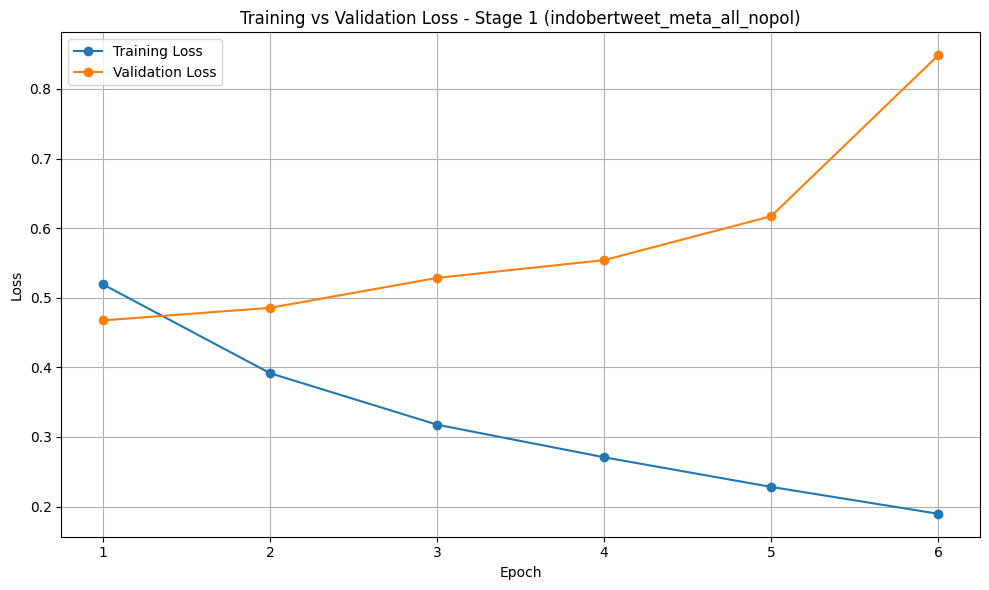

Stage 1 classification report -- test set (seed 42):
              precision    recall  f1-score   support

           0       0.87      0.86      0.86      2667
           1       0.74      0.75      0.74      1420

    accuracy                           0.82      4087
   macro avg       0.80      0.80      0.80      4087
weighted avg       0.82      0.82      0.82      4087

ROC-AUC (test): 0.8859
PR-AUC  (test): 0.8112


,Predicted Non-Toxic (0),Predicted Toxic (1)
Actual Non-Toxic (0),2295,372
Actual Toxic (1),357,1063


In [22]:
plot_loss(trainer_s1, f"Training vs Validation Loss - Stage 1 ({RUN_TAG})")

print(f"Stage 1 classification report -- test set (seed {FINAL_SEEDS[-1]}):")
print(classification_report(y_test, pred_label1))
print(f"ROC-AUC (test): {roc_auc_score(y_test, probs1_test):.4f}")
print(f"PR-AUC  (test): {average_precision_score(y_test, probs1_test):.4f}")

pd.DataFrame(confusion_matrix(y_test, pred_label1, labels=[0, 1]),
             index=["Actual Non-Toxic (0)", "Actual Toxic (1)"],
             columns=["Predicted Non-Toxic (0)", "Predicted Toxic (1)"])

# Stage 2 — Jenis Toksisitas (multi-label)

In [23]:
# Pool Stage 2: teks yang toxic secara majority (ditentukan di 00_make_splits.ipynb).
# text-only : 1 baris per teks, label jenis = majority vote
# metadata  : baris annotator yang menilai teks itu toxic, label jenis = label annotator tsb
df_s2 = df_main.merge(splits[["text_id", "s2_split"]].dropna(), on="text_id", how="inner")
df_s2 = df_s2[df_s2["toxicity"] == 1].reset_index(drop=True)

train_s2 = df_s2[df_s2["s2_split"] == "train"].reset_index(drop=True)
val_s2   = df_s2[df_s2["s2_split"] == "val"].reset_index(drop=True)
test_s2  = df_s2[df_s2["s2_split"] == "test"].reset_index(drop=True)

print("Stage 2 split sizes:", {"train": len(train_s2), "val": len(val_s2), "test": len(test_s2)})
print(pd.DataFrame({"train": train_s2[LABEL_COLS].sum(), "val": val_s2[LABEL_COLS].sum(),
                    "test": test_s2[LABEL_COLS].sum()}))
assert not (set(train_s2.text_id) & set(test_s2.text_id)), "LEAKAGE: teks yang sama ada di train & test"
assert not (set(train_s2.text_id) & set(val_s2.text_id)), "LEAKAGE: teks yang sama ada di train & val"

Stage 2 split sizes: {'train': 4079, 'val': 544, 'test': 1133}
                               train  val  test
insults                         2067  268   577
identity_attack                 2047  272   556
threat_incitement_to_violence    312   39    96
profanity_obscenity              849  128   216
sexually_explicit                174   29    61


In [24]:
# Random oversampling of minority-label rows for Stage 2 (multi-label). Only the TRAIN
# split is resampled -- val/test keep their natural distribution.
def oversample_multilabel(df, label_cols, random_state=42):
    max_count = df[label_cols].sum().max()
    parts = [df]
    for col in label_cols:
        n_needed = int(max_count - df[col].sum())
        if n_needed > 0:
            minority_rows = df[df[col] == 1]
            if len(minority_rows) > 0:
                parts.append(minority_rows.sample(n=n_needed, replace=True, random_state=random_state))
    return pd.concat(parts).sample(frac=1, random_state=random_state).reset_index(drop=True)


print("Before oversampling:", {c: int(train_s2[c].sum()) for c in LABEL_COLS})
train_s2_os = oversample_multilabel(train_s2, LABEL_COLS, random_state=42)
print("After oversampling:", {c: int(train_s2_os[c].sum()) for c in LABEL_COLS})

Before oversampling: {'insults': 2067, 'identity_attack': 2047, 'threat_incitement_to_violence': 312, 'profanity_obscenity': 849, 'sexually_explicit': 174}
After oversampling: {'insults': 3291, 'identity_attack': 3434, 'threat_incitement_to_violence': 2128, 'profanity_obscenity': 2995, 'sexually_explicit': 2184}


In [25]:
train_dataset_2, val_dataset_2, test_dataset_2 = build_datasets(
    [train_s2_os, val_s2, test_s2], stage=2,
    label_fn=lambda f: f[LABEL_COLS].astype(float).values.tolist()   # float: BCEWithLogitsLoss
)

Stage 2 max_len = 180
Contoh input: [CLS] etnis : sasak. agama : islam. disabilitas : no. lgbt : no. gender : m. usia : 36. domisili : mataram. pendidikan : sarjana ( s1 ). pekerjaan : bekerja. preferensi politik : 3. [SEP] tidak logis serta lucu juga ketika negeri lgbt mengadili negeri para arjuna tertawa terbahak bahak. yang logis p simbol wanita simbol pria [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [


In [26]:
def safe_auc(score_fn, labels, probs):
    """AUC macro; NaN kalau ada label yang di split ini cuma punya satu kelas."""
    try:
        return score_fn(labels, probs, average="macro")
    except ValueError:
        return float("nan")


def compute_metrics_s2(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(labels, preds),   # exact match (subset accuracy)
        "precision_micro": precision_score(labels, preds, average="micro", zero_division=0),
        "recall_micro": recall_score(labels, preds, average="micro", zero_division=0),
        "f1_micro": f1_score(labels, preds, average="micro", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": safe_auc(roc_auc_score, labels, probs),
        "pr_auc": safe_auc(average_precision_score, labels, probs),
    }

In [27]:
STUDY_NAME_S2 = f"s2_{RUN_TAG}_revisi"
OUTPUT_ROOT_S2 = f"./optuna_s2_{RUN_TAG}"
FINAL_DIR_S2 = f"./best_s2_{RUN_TAG}"
METRIC_S2 = "f1_macro"   # macro: setiap label (termasuk yang langka) berbobot sama


def suggest_params_s2(trial):
    # class_weight_alpha dihapus: Stage 2 tidak memakai class weight
    # (imbalance ditangani oversampling), jadi parameter itu tidak berpengaruh.
    return common_search_space(trial)


def build_trainer_s2(params, out_dir, trial=None, seed=SEED):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(LABEL_COLS),
        problem_type="multi_label_classification",
        id2label={i: l for i, l in enumerate(LABEL_COLS)},
        label2id={l: i for i, l in enumerate(LABEL_COLS)},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_layer(model, params["n_frozen_layers"], params["freeze_embeddings"])
    # weight_decay sekarang ikut dipakai (sebelumnya lupa)
    args = make_training_args(params, out_dir, len(train_dataset_2), seed, metric=METRIC_S2)

    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric=f"eval_{METRIC_S2}"))

    return Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset_2,
        eval_dataset=val_dataset_2,
        compute_metrics=compute_metrics_s2,
        callbacks=callbacks,
    )


def objective_s2(trial):
    params = suggest_params_s2(trial)
    out_dir = f"{OUTPUT_ROOT_S2}/trial_{trial.number}"
    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")
    trainer = None
    try:
        trainer = build_trainer_s2(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val {METRIC_S2} = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        cleanup(trainer, out_dir)

In [28]:
study_s2 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME_S2,
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),
    storage=f"sqlite:///optuna_s2_{RUN_TAG}.db",
    load_if_exists=True,
)
done = sum(t.state.is_finished() for t in study_s2.trials)
remaining = max(0, N_TRIALS_S2 - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s2.optimize(objective_s2, n_trials=remaining, gc_after_trial=True)

Trial selesai: 0 | sisa: 10

Trial 0
  learning_rate       : 1.70e-05
  warmup_ratio        : 0.19014286128198324
  batch_size          : 8
  num_train_epochs    : 3
  dropout             : 0.1116167224336399
  lr_scheduler_type   : linear
  weight_decay        : 0.07080725777960455
  n_frozen_layers     : 0
  freeze_embeddings   : False


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.712950,0.875987,0.369485,0.648333,0.528533,0.582335,0.534451,0.801586,0.603496
2,0.541515,0.812330,0.409926,0.668865,0.688859,0.678715,0.613073,0.808614,0.621491
3,0.403466,0.821301,0.415441,0.671466,0.697011,0.684000,0.621530,0.814303,0.626834


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Trial 0 selesai | best val f1_macro = 0.6215

Trial 1
  learning_rate       : 1.23e-05
  warmup_ratio        : 0.03636499344142013
  batch_size          : 32
  num_train_epochs    : 5
  dropout             : 0.15824582803960838
  lr_scheduler_type   : linear
  weight_decay        : 0.029214464853521818
  n_frozen_layers     : 2
  freeze_embeddings   : True


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



... (31 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.839920,0.937595,0.237132,0.530576,0.400815,0.456656,0.456933,0.769248,0.556080
2,0.696335,0.854280,0.389706,0.632628,0.690217,0.660169,0.597261,0.816664,0.606367
3,0.495107,0.879415,0.386029,0.630896,0.726902,0.675505,0.598355,0.826242,0.608706
4,0.563197,0.907774,0.387868,0.637037,0.701087,0.667529,0.598624,0.822046,0.605077
5,0.441049,0.898569,0.433824,0.659062,0.706522,0.681967,0.594938,0.821896,0.604842
6,0.374737,0.925367,0.420956,0.653652,0.705163,0.678431,0.599931,0.823908,0.609334


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead un

Trial 9 selesai | best val f1_macro = 0.5999


In [29]:
study_s2.trials

[FrozenTrial(number=0, state=<TrialState.COMPLETE: 1>, values=[0.6215302774155128], datetime_start=datetime.datetime(2026, 11, 11, 11, 15, 12, 439760), datetime_complete=datetime.datetime(2026, 11, 11, 11, 25, 44, 156151), params={'learning_rate': 1.7015140382951922e-05, 'warmup_ratio': 0.19014286128198324, 'batch_size': 8, 'num_train_epochs': 3, 'dropout': 0.1116167224336399, 'lr_scheduler_type': 'linear', 'weight_decay': 0.07080725777960455, 'n_frozen_layers': 0, 'freeze_embeddings': False}, user_attrs={}, system_attrs={}, intermediate_values={1: 0.5344513718911642, 2: 0.6130726799077002, 3: 0.6215302774155128}, distributions={'learning_rate': FloatDistribution(high=6e-05, log=True, low=8e-06, step=None), 'warmup_ratio': FloatDistribution(high=0.2, log=False, low=0.0, step=None), 'batch_size': CategoricalDistribution(choices=(8, 16, 32)), 'num_train_epochs': IntDistribution(high=8, log=False, low=3, step=1), 'dropout': FloatDistribution(high=0.3, log=False, low=0.1, step=None), 'lr_s

In [30]:
print(f"Best trial #{study_s2.best_trial.number} | val {METRIC_S2} = {study_s2.best_value:.4f}")
for k, v in study_s2.best_params.items():
    print(f"  {k:20s}: {v}")
optuna.visualization.plot_param_importances(study_s2).show()
optuna.visualization.plot_optimization_history(study_s2).show()

Best trial #4 | val f1_macro = 0.6248
  learning_rate       : 3.714685453845735e-05
  warmup_ratio        : 0.18281154412075726
  batch_size          : 8
  num_train_epochs    : 3
  dropout             : 0.19277494856131036
  lr_scheduler_type   : linear
  weight_decay        : 0.038041122088768545
  n_frozen_layers     : 1
  freeze_embeddings   : False


In [31]:
test_info_s2 = test_s2[ID_COLS + DEMO_SAVE_COLS].copy()
for l in LABEL_COLS:
    test_info_s2[f"true_{l}"] = test_s2[l].astype(int).values

preds_s2_all = []
for i, seed in enumerate(FINAL_SEEDS):
    out_dir = f"{FINAL_DIR_S2}_seed{seed}"
    trainer_s2 = build_trainer_s2(study_s2.best_params, out_dir, seed=seed)
    trainer_s2.train()
    pred2 = trainer_s2.predict(test_dataset_2)
    probs = 1 / (1 + np.exp(-pred2.predictions.astype(np.float32)))

    out = test_info_s2.copy()
    out["seed"] = seed
    for j, l in enumerate(LABEL_COLS):
        out[f"prob_{l}"] = probs[:, j]
    preds_s2_all.append(out)
    y_true = out[[f"true_{l}" for l in LABEL_COLS]].values
    print(f"seed {seed}: macro F1 = {f1_score(y_true, (probs >= 0.5).astype(int), average='macro', zero_division=0):.4f}")
    if i < len(FINAL_SEEDS) - 1:
        cleanup(trainer_s2, out_dir)

preds_s2 = pd.concat(preds_s2_all, ignore_index=True)
preds_s2.to_csv(f"{OUT_DIR}/preds_{RUN_TAG}_s2.csv", index=False)
print("Prediksi tersimpan:", f"{OUT_DIR}/preds_{RUN_TAG}_s2.csv")

trainer_s2.save_model(FINAL_DIR_S2)
tokenizer.save_pretrained(FINAL_DIR_S2)
model_s2 = trainer_s2.model
y2_true = test_info_s2[[f"true_{l}" for l in LABEL_COLS]].values
probs2_test = probs
pred_label2 = (probs2_test >= 0.5).astype(int)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.686881,0.833764,0.398897,0.648098,0.648098,0.648098,0.561894,0.820847,0.632724
2,0.508383,0.812762,0.408088,0.667969,0.697011,0.682181,0.624805,0.823759,0.634937
3,0.374323,0.856647,0.424632,0.664557,0.713315,0.688073,0.622076,0.821856,0.633108


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



seed 42: macro F1 = 0.6220
Prediksi tersimpan: /kaggle/working/preds_indobertweet_meta_all_nopol_s2.csv


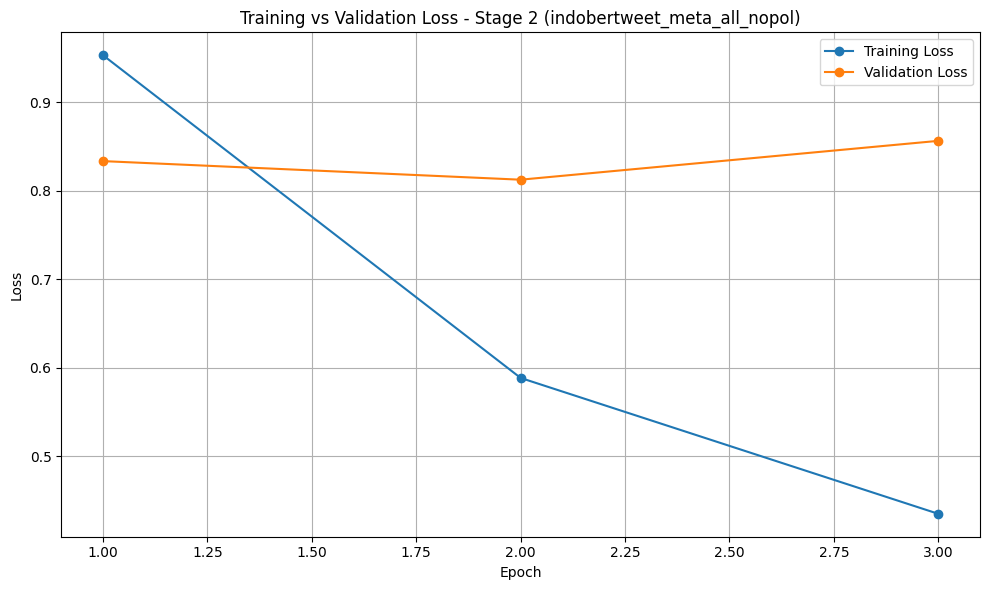

Stage 2 classification report -- test set (seed 42):
                               precision    recall  f1-score   support

                      insults       0.73      0.72      0.73       577
              identity_attack       0.74      0.77      0.75       556
threat_incitement_to_violence       0.42      0.42      0.42        96
          profanity_obscenity       0.57      0.64      0.60       216
            sexually_explicit       0.57      0.66      0.61        61

                    micro avg       0.68      0.71      0.69      1506
                    macro avg       0.60      0.64      0.62      1506
                 weighted avg       0.68      0.71      0.69      1506
                  samples avg       0.68      0.71      0.67      1506



,Label,TN,FP,FN,TP
0,insults,400,156,159,418
1,identity_attack,423,154,126,430
2,threat_incitement_to_violence,981,56,56,40
3,profanity_obscenity,810,107,77,139
4,sexually_explicit,1042,30,21,40


In [32]:
plot_loss(trainer_s2, f"Training vs Validation Loss - Stage 2 ({RUN_TAG})")

print(f"Stage 2 classification report -- test set (seed {FINAL_SEEDS[-1]}):")
print(classification_report(y2_true, pred_label2, target_names=LABEL_COLS, zero_division=0))

cm_results = []
for i, label in enumerate(LABEL_COLS):
    tn, fp, fn, tp = confusion_matrix(y2_true[:, i], pred_label2[:, i], labels=[0, 1]).ravel()
    cm_results.append({"Label": label, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
pd.DataFrame(cm_results)

# Simpan Output

In [34]:
for d in [globals().get("FINAL_DIR"), globals().get("FINAL_DIR_S2")]:   # aman kalau satu stage dilewati
    if d and os.path.isdir(d):
        shutil.make_archive(f"{OUT_DIR}/{os.path.basename(d)}", "zip", root_dir=".", base_dir=d)
        print("ZIP berhasil dibuat:", f"{OUT_DIR}/{os.path.basename(d)}.zip")
print("File prediksi untuk 99_compare.ipynb:")
for f in sorted(os.listdir(OUT_DIR)):
    if f.startswith(f"preds_{RUN_TAG}"):
        print("  ", f)

ZIP berhasil dibuat: /kaggle/working/best_s1_indobertweet_meta_all_nopol.zip
ZIP berhasil dibuat: /kaggle/working/best_s2_indobertweet_meta_all_nopol.zip
File prediksi untuk 99_compare.ipynb:
   preds_indobertweet_meta_all_nopol_s1.csv
   preds_indobertweet_meta_all_nopol_s2.csv
